In [24]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [25]:
# Imports
from Experiment_4.ParametricWMTask import generate_trials
#from Experiment_5.SiegelMillerTask import generate_trials
import networkx as nx
import pandas as pd
import matplotlib
import torch
import matplotlib.pyplot as plt
from matplotlib import gridspec
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import seaborn as sns
from Experiment_4.net import *
import os
import numpy as np
import statsmodels.api as sm
import scipy.optimize as opt
import math
#from psychometrics import *
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
import networkx as nx
from sklearn.cluster import KMeans

plt.rcParams["axes.grid"] = False
from sklearn.manifold import TSNE

matplotlib.rcParams['axes.linewidth'] = .75

In [26]:
def compute_var(variance, n):
    return np.sum(variance[n:])

def compute_p(k, null_k):
    return (np.sum(null_k < k) / len(null_k))

In [27]:
# Load data
df_list = []
for filename in os.listdir('Experiment_4/Results_4'):
    f = os.path.join('Experiment_4/Results_4', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list, ignore_index=True)
#original_df = original_df[original_df.mse_z < .035]
#original_df = original_df[original_df.n==100]

In [28]:
df = original_df.copy()

# Restrict to networks with dim and compute variance above dim
dim =7
#df = df[df.dim == dim]
#df = df[df.k >= dim]
df['var'] = df.variance.apply(lambda x: compute_var(x, dim))
df['k_inertia'] = df.inertia.apply(lambda x: x[dim - 1])
#df['var'] = np.log(df['var'])
df.sort_values('var', ascending=True)

,model_id,w_rec,w_in,w_out,bias,mse_z,epochs,sigma_rec,sigma_in,weight_decay,...,lambda_curve,n,lvar,dim,k,inertia,null_inertia,variance,var,k_inertia
0,m09LJLGJ,"[[0.0, 0.0011539913, 0.012903868, -0.024848085...","[[-0.07165045, 0.16800795], [0.045852825, 0.15...","[[-0.002166198, 0.012694674, -0.0136286365, 0....","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.040119,1000,0.0,0.1,0.02,...,0.0,125,10.0,7,6,"[0.9672712, 0.6775414666666667, 0.352133766666...","[[0.9831250703841286, 0.9952298039600787, 0.99...","[0.5415606, 0.343667, 0.056109756, 0.035090756...",0.000054,0.000798


In [29]:

## Restrict connectivity to PCs
model_data = df[df.model_id == 'm09LJLGJ']
dim = model_data['dim'].item()
net = Net(n=125,input_size = 2,dale=False,base_in=0.2)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.input_layer.bias.data = torch.tensor(0.2).float()
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.output_layer.bias.data = torch.tensor(-0.2).float()
net.sigma_in = 0.
net.sigma_rec = 0.
u, z, mask, conditions = generate_trials(
    n_trials=25)

# COMPUTE RESPONSES
x = net(u).detach().cpu().numpy()
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'theta': conditions[k]['theta'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['theta']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
#df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T
#responses = responses[np.mean(responses, axis=1) >.025, ]
# responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]

## clustering


w_rec = net.recurrent_layer.weight.data
w_in = net.input_layer.weight.data
w_out = net.output_layer.weight.data
pca = PCA(n_components = 2).fit(responses.T)
U = pca.components_
A = w_rec@U.T
b = net.recurrent_layer.bias.data.detach().cpu().numpy()

#A = np.concatenate((A, b[:, None]), axis=1)
# Cluster hyperplanes
k = 7
clustering = KMeans(n_clusters=k, n_init=20).fit(A)

# Compute magnitudes of each hyperplane
magnitudes = np.linalg.norm(A, axis=1)

# Construct Q of shape N x k
q = torch.zeros((A.shape[0], k))
for cluster in range(k):
    for neuron in range(A.shape[0]):
        if np.isin(neuron, np.argwhere(clustering.labels_==cluster)):
            q[neuron, cluster] = torch.tensor(magnitudes[neuron]).float()
q = q/torch.linalg.norm(q,dim=0)

# Construct reduced model
w_rec_reduced = q.t() @ w_rec @ q
w_in_reduced = q.t() @ w_in
w_out_reduced = w_out @ q

# Initialize reduced model
reduced_net = Net(n=k, input_size=2, dale=False)
reduced_net.recurrent_layer.weight.data = w_rec_reduced
reduced_net.recurrent_layer.bias.data = q.t()@torch.tensor(model_data['bias'].item())
reduced_net.input_layer.weight.data = w_in_reduced
reduced_net.output_layer.weight.data = w_out_reduced


reduced_net.sigma_in = 0.1
reduced_net.sigma_rec = 0
net.sigma_in = 0.
net.sigma_rec = 0





In [30]:
from mpl_toolkits.axes_grid1 import AxesGrid

def shiftedColorMap(cmap, start=0, midpoint=0.5, stop=1.0, name='shiftedcmap'):
    '''
    Function to offset the "center" of a colormap. Useful for
    data with a negative min and positive max and you want the
    middle of the colormap's dynamic range to be at zero.

    Input
    -----
      cmap : The matplotlib colormap to be altered
      start : Offset from lowest point in the colormap's range.
          Defaults to 0.0 (no lower offset). Should be between
          0.0 and `midpoint`.
      midpoint : The new center of the colormap. Defaults to 
          0.5 (no shift). Should be between 0.0 and 1.0. In
          general, this should be  1 - vmax / (vmax + abs(vmin))
          For example if your data range from -15.0 to +5.0 and
          you want the center of the colormap at 0.0, `midpoint`
          should be set to  1 - 5/(5 + 15)) or 0.75
      stop : Offset from highest point in the colormap's range.
          Defaults to 1.0 (no upper offset). Should be between
          `midpoint` and 1.0.
    '''
    cdict = {
        'red': [],
        'green': [],
        'blue': [],
        'alpha': []
    }

    # regular index to compute the colors
    reg_index = np.linspace(start, stop, 257)

    # shifted index to match the data
    shift_index = np.hstack([
        np.linspace(0.0, midpoint, 128, endpoint=False), 
        np.linspace(midpoint, 1.0, 129, endpoint=True)
    ])

    for ri, si in zip(reg_index, shift_index):
        r, g, b, a = cmap(ri)

        cdict['red'].append((si, r, r))
        cdict['green'].append((si, g, g))
        cdict['blue'].append((si, b, b))
        cdict['alpha'].append((si, a, a))

    newcmap = matplotlib.colors.LinearSegmentedColormap(name, cdict)
    plt.register_cmap(cmap=newcmap)

    return newcmap

/Users/cl1704/anaconda3/envs/clustering_env/lib/python3.8/site-packages/networkx/drawing/nx_pylab.py:433: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_34812/1461711079.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  orig_cmap = matplotlib.cm.get_cmap('icefire', 50)


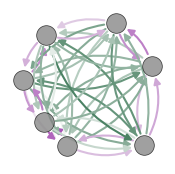

In [31]:

w_rec_reduced = w_rec_reduced - np.diag(np.diag(w_rec_reduced))
G = nx.DiGraph((w_rec_reduced).T.numpy(), create_using=nx.DiGraph)

# Calculate positions
x =  reduced_net(u).detach().numpy()
x = x.reshape(-1, x.shape[2]).T
x_proj = PCA(n_components = 2).fit_transform(x)
pos = {}
for i in range(x_proj.shape[0]):
    pos[i]= x_proj[i,:]
#pos = nx.spring_layout(G,k=1)
fig = plt.figure(figsize=(2,2))
gs = gridspec.GridSpec(1,1, figure=fig)

ax=fig.add_subplot(gs[0,0])

nx.draw_networkx_nodes(G, pos,cmap=plt.get_cmap('coolwarm'), node_color='gray',
                       edgecolors='black',
                       linewidths=.5,
                         node_size=200,
                       alpha=.75,
                      ax=ax)

edges,weights = zip(*nx.get_edge_attributes(G,'weight').items())
center= 1 - np.max(weights) / (np.max(weights) + abs(np.min(weights)))
#orig_cmap = matplotlib.cm.coolwarm
orig_cmap = matplotlib.cm.get_cmap('icefire', 50)
orig_cmap = sns.diverging_palette(145, 300, s=60, as_cmap=True)
#shrunk_cmap = shiftedColorMap(orig_cmap, start=0, midpoint=center, stop=1, name='shrunk')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
nx.draw_networkx_edges(G, pos, width = 1.5,edge_color=weights,edge_cmap=orig_cmap,connectionstyle="Arc3, rad=.25",arrowsize=10, alpha = 1,ax=ax)
 
#nx.draw_networkx_labels(G, pos,{0:'1',1:'2',2:'3'}, font_size=8, font_color="k")
fig.savefig('Figures/circuit.jpg',
    format='jpeg',
    dpi=450,
)

In [7]:
pos

NameError: name 'pos' is not defined